## Environment check

In [1]:
import json, os, sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")

import numpy as np
np.random.seed(20260815)

DATASET_AVAILABLE = (REPO / "release_v0" / "meta" / "meta.csv").exists()
EV = REPO / "research" / "evidence" / "derm7pt_v1"
print(f"repo: {REPO}")
print(f"Derm7pt dataset present: {DATASET_AVAILABLE}")
print(f"evidence dir present:    {EV.exists()}")

repo: E:\Studies\Research\MedGuard-RAG-Journal
Derm7pt dataset present: True
evidence dir present:    True


## One image, end to end

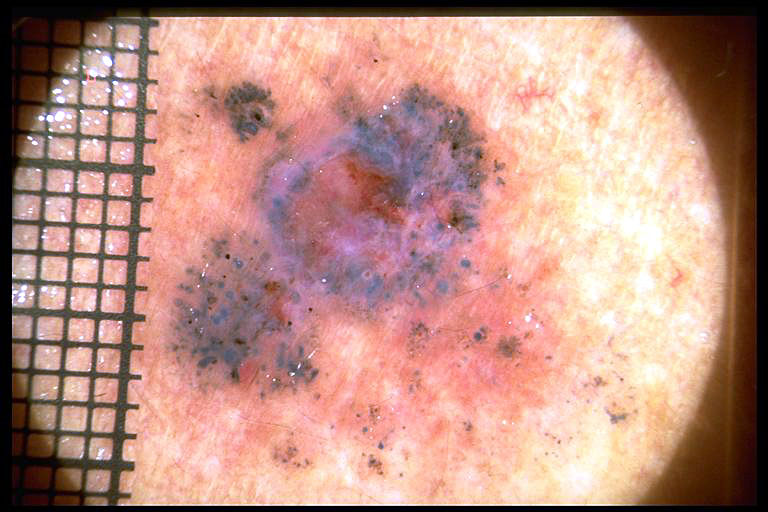

E:\Studies\Research\MedGuard-RAG-Journal\venv_win\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


diagnosis=MEL  confidence=0.88  domain gated=False (score 0.944)


## Case derm7pt-12

**Assessment: excision** — score 4 >= 3 · views agree

### Next step

Excision — see DOI:10.1016/j.jaad.2018.08.055 (quoted below).

| assessment | result |
|---|---|
| Image pattern model | **melanoma** (high model agreement (0.88)) |
| 7-point checklist | **score 4** (threshold for excision: 3) |
| Checklist implies | **excision** — score 4 >= 3 |

### Dermoscopic criteria

| criterion | observed | points |
|---|---|---:|
| pigment network (major, max 2) | absent | 0 |
| blue whitish veil (major, max 2) | present | 2 |
| vascular structures (major, max 2) | within regression | 0 |
| streaks (minor, max 1) | absent | 0 |
| pigmentation (minor, max 1) | absent | 0 |
| dots and globules (minor, max 1) | irregular | 1 |
| regression structures (minor, max 1) | combinations | 1 |

**Total: 4**

_This verdict hinges on blue whitish veil (present, +2): read as absent, the score falls to 2 and clinical follow up applies._

### Authoritative guidance

> Surgical excision with histologically negative margins is the recommended and first-line treatment for primary CM of any thickness, as well as for melanoma in situ. Surgical margins should be based on tumor thickness.

— DOI:10.1016/j.jaad.2018.08.055 · 2019 · ✓

_+2 more recommendation(s) on request._

---
_Decision support only. The diagnosis is produced by a frozen image model and a published checklist; it has not been validated against clinician judgement._

In [2]:
if DATASET_AVAILABLE:
    from IPython.display import Image as IPyImage, Markdown, display
    from medguard_v2.data.derm7pt import load_cases
    from medguard_v2.pipeline.predict_one import predict_one

    cases = {f"derm7pt-{c.case_num}": c for c in load_cases()}
    case = cases["derm7pt-12"]  # classifier and checklist AGREE: melanoma, score 4 >= 3
    display(IPyImage(filename=str(case.derm_path), width=360))
    pred = predict_one(case.derm_path, sex=case.sex, location=case.location,
                       elevation=case.elevation, case_id="derm7pt-12")
    print(f"diagnosis={pred.diagnosis}  confidence={pred.confidence:.2f}  "
          f"domain gated={pred.domain['gated']} (score {pred.domain['score']:.3f})")
    display(Markdown(pred.report_markdown))
else:
    print("Dataset absent - see the committed outputs of this cell.")

## Generation under verification

In [3]:
if DATASET_AVAILABLE:
    from medguard_v2.evidence.summary import generate_case_brief
    from medguard_v2.evidence.render import render_markdown
    from IPython.display import Markdown, display

    c = pred.contract  # same agreeing case as above
    good = (f"The 7-point score is {c.score.score_min}, at or above the excision "
            f"threshold of 3, so the checklist-implied action is {c.criteria_implied_action}. "
            "The pattern model and the checklist agree on this case.")
    def brief_chat(messages):
        return good

    brief = generate_case_brief(c, brief_chat)
    print(f"verified={brief.verified} attempts={brief.attempts} fallback={brief.fallback_used}")
    print("(measured on the real model: 203/203 briefs verified - case_brief_measurement.json)")
    display(Markdown(render_markdown(c, brief)))
else:
    print("Dataset absent - see committed outputs.")

verified=True attempts=1 fallback=False
(measured on the real model: 203/203 briefs verified - case_brief_measurement.json)


## Case derm7pt-12

**Assessment: excision** — score 4 >= 3 · views agree

_AI summary (verified against the decision record):_ The 7-point score is 4, at or above the excision threshold of 3, so the checklist-implied action is excision. The pattern model and the checklist agree on this case.

### Next step

Excision — see DOI:10.1016/j.jaad.2018.08.055 (quoted below).

| assessment | result |
|---|---|
| Image pattern model | **melanoma** (high model agreement (0.88)) |
| 7-point checklist | **score 4** (threshold for excision: 3) |
| Checklist implies | **excision** — score 4 >= 3 |

### Dermoscopic criteria

| criterion | observed | points |
|---|---|---:|
| pigment network (major, max 2) | absent | 0 |
| blue whitish veil (major, max 2) | present | 2 |
| vascular structures (major, max 2) | within regression | 0 |
| streaks (minor, max 1) | absent | 0 |
| pigmentation (minor, max 1) | absent | 0 |
| dots and globules (minor, max 1) | irregular | 1 |
| regression structures (minor, max 1) | combinations | 1 |

**Total: 4**

_This verdict hinges on blue whitish veil (present, +2): read as absent, the score falls to 2 and clinical follow up applies._

### Authoritative guidance

> Surgical excision with histologically negative margins is the recommended and first-line treatment for primary CM of any thickness, as well as for melanoma in situ. Surgical margins should be based on tumor thickness.

— DOI:10.1016/j.jaad.2018.08.055 · 2019 · ✓

_+2 more recommendation(s) on request._

---
_Decision support only. The diagnosis is produced by a frozen image model and a published checklist; it has not been validated against clinician judgement._

## The measured system

In [4]:
import pandas as pd
S = json.loads((EV / "paper_metrics_summary.json").read_text(encoding="utf-8"))

perc = pd.DataFrame([
    ["Derm7pt test (395)", "5-class acc", S["perception_derm7pt"]["classifier_5class"]["argmax"]["accuracy"]],
    ["Derm7pt test", "MEL AUROC", S["perception_derm7pt"]["melanoma_auroc"]["point"]],
    ["Derm7pt test", "criteria binary-F1 (DermAgent 0.6506)", S["perception_derm7pt"]["criteria_aggregate"]["binary_concept_f1_macro"]],
    ["BCN test (712)", "MEL AUROC (promoted recipe)", S["perception_bcn"]["promoted_recipe_post_hoc"]["mel_auroc"]],
    ["HAM E3 (1595)", "7-class acc (promoted recipe)", S["perception_ham"]["promoted_recipe_post_hoc"]["e3_seven_class"]["accuracy"]],
    ["HAM sealed (1495)", "5-group acc (post-hoc)", S["perception_ham"]["promoted_recipe_post_hoc"]["sealed_five_group"]["accuracy"]],
], columns=["dataset", "metric", "value"])
display(perc)

ep = S["agent_eval"]["endpoints"]
agent_tbl = pd.DataFrame([
    ["counterfactual accuracy (exact)", ep["counterfactual_accuracy"]["correct"]],
    ["citation resolvability", ep["citation_resolvability"]["resolvability"]],
    ["refusal correctness", ep["refusal_correctness"]["overall"]],
    ["absence disclosure", ep["absence_disclosure"]["states_absence"]],
    ["management fabrication", ep["management_fabrication"]["rate"]],
    ["case briefs verified", S["agent_eval"]["case_briefs"]["verified_rate"]],
], columns=["agent endpoint", "value"])
display(agent_tbl)

rg = S["ragas"]
display(pd.DataFrame([
    ["faithfulness (median-of-3 judge)", rg["overall_faithfulness"]],
    ["guideline-grounded faithfulness", rg["by_grounding"]["guideline"]["mean"]],
    ["combined (deduplicated)", rg["combined_faithfulness"]],
    ["answer relevancy", rg["answer_relevancy"]],
], columns=["RAGAS", "value"]))

,dataset,metric,value
0,Derm7pt test (395),5-class acc,0.7620
1,Derm7pt test,MEL AUROC,0.9151
2,Derm7pt test,criteria binary-F1 (DermAgent 0.6506),0.7168
3,BCN test (712),MEL AUROC (promoted recipe),0.8719
4,HAM E3 (1595),7-class acc (promoted recipe),0.8589
5,HAM sealed (1495),5-group acc (post-hoc),0.8809


,agent endpoint,value
0,counterfactual accuracy (exact),0.9622
1,citation resolvability,1.0000
2,refusal correctness,1.0000
3,absence disclosure,1.0000
4,management fabrication,0.0000
5,case briefs verified,1.0000


,RAGAS,value
0,faithfulness (median-of-3 judge),0.8447
1,guideline-grounded faithfulness,0.9830
2,combined (deduplicated),0.9248
3,answer relevancy,0.9237
